# DSC 411/511 Project
# Notebook 09: RQ7 (new): The Protection Gap: Do Poorer, Renter-Heavy or Older Neighbourhoods File Fewer Claims When the Flood Is the Same?

**Class topics:** Lecture 03 (aggregation, discretization, sampling), Lecture 05/07 (tree models and evaluation with a
grouped split), Lecture 09-10 (spatial structure, clustering), plus two extensions: **count models** (Poisson and
negative binomial regression) and **local spatial autocorrelation (LISA)** for gap hotspots.

---

**How this question was derived.** Notebook 08 looked *inside* the claims: once a claim exists, is it paid? But a
household that has no flood policy never files a claim at all. So the claims table hides a bigger inequality: the
people who are flooded but **not insured**. This is often called the **protection gap**. Published work finds that
NFIP take-up is low outside the mapped floodplain (Bradt, Kousky & Wing 2021: 4.1% outside vs 29.9% inside the SFHA),
that about 70% of expected flood losses of single-family homes are uninsured (Amornsiripanitch et al. 2025), and that
Risk Rating 2.0 reduced take-up more in low-income ZIP codes (Gourevitch, Snyder & Kousky 2025).

Here we move from the **claim** to the **place**. For every census tract that was hit by a 2020-2025 storm or by very
heavy rain, we count NFIP claims per 1,000 housing units and ask:

> **RQ7. Do census tracts with lower income, more renters or older housing file fewer NFIP claims per housing unit
> exposed, even when storm and rain hazard was similar? And is the gap caused by fewer policies (take-up) or by fewer
> claims per policy?**

**The key identity.** Claims per housing unit can be split into two parts:

$$\frac{\text{claims}}{\text{housing units}} = \underbrace{\frac{\text{policies in force}}{\text{housing units}}}_{\text{take-up}} \times \underbrace{\frac{\text{claims}}{\text{policies in force}}}_{\text{claim rate per policy}}$$

A tract can have few claims because few people are insured (take-up), or because insured homes did not file / were not
damaged (claim rate). We use the OpenFEMA **NFIP Redacted Policies v3** file (74.8 million policy records) to measure
policies in force by tract, so we can separate the two. (The older `FimaNfipPolicies` v2 dataset is deprecated; v3 has the
same content.)

---
# Section 0: Setup

In [1]:
import sys
import json
import time
import zipfile
import datetime
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
import pyarrow.parquet as pq
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lightgbm as lgb
from sklearn.neighbors import BallTree
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_poisson_deviance

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import RAW_DIR, PROCESSED_DIR, TABLE_DIR, FIGURE_DIR, SEED, show_answer_numbers

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)
EARTH_RADIUS_KM = 6371.0
NON_CONUS_STATE_FIPS = ['02', '15', '60', '66', '69', '72', '78']

---
## 0.1 Files this notebook needs (downloaded here if missing)

Notebook 00 downloads the NFIP claims, PRISM, HURDAT2, boundaries, NRI and seven ACS tables. Notebook 09 needs a few
**extra** files. They are downloaded below only if they are not already in `data_raw/`:

| File | Size | Source |
|---|---|---|
| `census/2023_Gaz_tracts_national.zip` | 2.4 MB | Census 2023 Gazetteer (tract internal points, land area) |
| `census/tab20_tract20_tract10_natl.txt` | 19 MB | Census 2020-2010 tract relationship file |
| `census/acsdt5y2023-b25001.dat` | 18 MB | ACS 2019-2023 Summary File: housing units |
| `census/acsdt5y2023-b25034.dat` | 50 MB | ACS 2019-2023 Summary File: year structure built |
| `census/acsdt5y2023-{b25003,b19013,b25035,b01003}.dat` | | already downloaded by notebook 00 (re-checked here) |
| `policies/NfipPoliciesV3.parquet` | **about 2.5 GB** | OpenFEMA NFIP Redacted Policies v3. Large: the download can take 10-30 minutes. It is only needed the first time, because the result is cached in `data_processed/policies_in_force_by_tract.parquet` |

Notebook 09 also uses files from notebook 00: `data_raw/prism/*.zip`, `data_raw/boundaries/ne_10m_coastline.zip`,
`data_raw/boundaries/cb_2023_us_state_20m.zip`, `data_raw/nri/NRI_Table_Counties.zip`,
`data_processed/hurdat2_tracks_2019_2025.parquet` and `data_processed/claims_merged_2020_2025.parquet`.

In [2]:
import requests
from pathlib import Path


def download_if_missing(url, destination, min_size_bytes=1000, timeout=600):
    """Download a file only if we do not already have it (same helper as notebook 00). Returns the local path."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size >= min_size_bytes:
        return destination
    print(f'Downloading {url} ...')
    with requests.get(url, stream=True, timeout=timeout) as response:
        response.raise_for_status()
        temporary_path = destination.with_suffix(destination.suffix + '.part')
        with open(temporary_path, 'wb') as file_handle:
            for chunk in response.iter_content(chunk_size=1 << 20):
                file_handle.write(chunk)
        temporary_path.rename(destination)
    return destination


CENSUS_DIR = RAW_DIR / 'census'
ACS_BASE_URL = 'https://www2.census.gov/programs-surveys/acs/summary_file/2023/table-based-SF/data/5YRData/'
EXTRA_FILES = {
    CENSUS_DIR / '2023_Gaz_tracts_national.zip':
        'https://www2.census.gov/geo/docs/maps-data/data/gazetteer/2023_Gazetteer/2023_Gaz_tracts_national.zip',
    CENSUS_DIR / 'tab20_tract20_tract10_natl.txt':
        'https://www2.census.gov/geo/docs/maps-data/data/rel2020/tract/tab20_tract20_tract10_natl.txt',
}
for acs_table in ['b25001', 'b25003', 'b19013', 'b25034', 'b25035', 'b01003']:
    EXTRA_FILES[CENSUS_DIR / f'acsdt5y2023-{acs_table}.dat'] = f'{ACS_BASE_URL}acsdt5y2023-{acs_table}.dat'
for local_path, url in EXTRA_FILES.items():
    download_if_missing(url, local_path, min_size_bytes=100_000)

# The 2.5 GB policies file is only needed if the policies-in-force cache does not exist yet.
POLICIES_URL = 'https://www.fema.gov/about/reports-and-data/openfema/v3/NfipPoliciesV3.parquet'
if not (PROCESSED_DIR / 'policies_in_force_by_tract.parquet').exists():
    download_if_missing(POLICIES_URL, RAW_DIR / 'policies' / 'NfipPoliciesV3.parquet', min_size_bytes=1_000_000_000, timeout=3600)
for local_path in list(EXTRA_FILES) + [RAW_DIR / 'policies' / 'NfipPoliciesV3.parquet']:
    size_text = f'{local_path.stat().st_size / 1e6:,.1f} MB' if local_path.exists() else 'not present (cache used)'
    print(f'{str(local_path.relative_to(RAW_DIR)):<45} {size_text}')

census/2023_Gaz_tracts_national.zip           2.4 MB
census/tab20_tract20_tract10_natl.txt         18.7 MB
census/acsdt5y2023-b25001.dat                 17.8 MB
census/acsdt5y2023-b25003.dat                 26.9 MB
census/acsdt5y2023-b19013.dat                 17.9 MB
census/acsdt5y2023-b25034.dat                 50.0 MB
census/acsdt5y2023-b25035.dat                 15.4 MB
census/acsdt5y2023-b01003.dat                 18.3 MB
policies/NfipPoliciesV3.parquet               2,520.5 MB


---
# Section 1: The Unit of Analysis: Census Tracts (Lecture 03, aggregation)

**Why tracts?** Block groups are smaller, but most block groups have zero claims and very few policies, so rates would
be mostly noise. Counties are too large: a county mixes a flooded coast with dry inland towns. Tracts (about 4,000
people, 1,700 housing units) are a good middle level, and ACS publishes all the variables we need for them.

**A practical problem: two tract vintages.** ACS 2019-2023 uses **2020** tract codes. Some NFIP claims and policies still
carry **2010** tract codes. We move 2010-coded counts to 2020 tracts with the Census 2020-2010 tract relationship file,
splitting each 2010 tract by its share of land area.

In [3]:
gazetteer = pd.read_csv(RAW_DIR / 'census' / '2023_Gaz_tracts_national.zip', sep='\t', dtype={'GEOID': str})
gazetteer.columns = [column.strip() for column in gazetteer.columns]
tracts = gazetteer[['GEOID', 'USPS', 'ALAND', 'INTPTLAT', 'INTPTLONG']].rename(
    columns={'GEOID': 'tract_geoid', 'USPS': 'state', 'ALAND': 'land_area_m2', 'INTPTLAT': 'latitude', 'INTPTLONG': 'longitude'})
tracts = tracts[~tracts['tract_geoid'].str[:2].isin(NON_CONUS_STATE_FIPS)].reset_index(drop=True)
tracts['county_geoid'] = tracts['tract_geoid'].str[:5]
print(f'Contiguous-U.S. census tracts (2020 vintage): {len(tracts):,}')

# Relationship file: 2010 tract -> 2020 tract, with land-area weights.
relationship = pd.read_csv(RAW_DIR / 'census' / 'tab20_tract20_tract10_natl.txt', sep='|',
                           dtype={'GEOID_TRACT_20': str, 'GEOID_TRACT_10': str})
relationship['weight'] = np.where(relationship['AREALAND_TRACT_10'] > 0,
                                  relationship['AREALAND_PART'] / relationship['AREALAND_TRACT_10'],
                                  relationship['AREAWATER_PART'] / relationship['AREAWATER_TRACT_10'].replace(0, np.nan))
relationship['weight'] = relationship['weight'].fillna(0)
relationship['weight'] = relationship['weight'] / relationship.groupby('GEOID_TRACT_10')['weight'].transform('sum').replace(0, np.nan)
relationship = relationship.dropna(subset=['weight'])[['GEOID_TRACT_10', 'GEOID_TRACT_20', 'weight']]
TRACTS_2020 = set(tracts['tract_geoid'])


def counts_to_2020_tracts(counts_by_tract, label):
    """Move counts indexed by tract code (2010 or 2020 vintage) onto 2020 tracts."""
    counts_by_tract = counts_by_tract[counts_by_tract.index.notna()]
    is_2020_code = counts_by_tract.index.isin(TRACTS_2020)
    direct = counts_by_tract[is_2020_code]
    old_codes = counts_by_tract[~is_2020_code].rename_axis('GEOID_TRACT_10').reset_index(name='value')
    moved = old_codes.merge(relationship, on='GEOID_TRACT_10', how='inner')
    moved['value'] = moved['value'] * moved['weight']
    moved_sum = moved.groupby('GEOID_TRACT_20')['value'].sum()
    total = counts_by_tract.sum()
    print(f'{label}: {direct.sum() / total * 100:.1f}% on 2020 codes, {moved_sum.sum() / total * 100:.1f}% moved from 2010 codes, '
          f'{(total - direct.sum() - moved_sum.sum()) / total * 100:.1f}% not placed')
    return direct.add(moved_sum, fill_value=0)

Contiguous-U.S. census tracts (2020 vintage): 83,777


---
# Section 2: ACS Housing Data by Tract

| Variable | ACS table | Meaning |
|---|---|---|
| housing units | B25001 | all housing units, **including vacant and seasonal homes** (second homes can also hold NFIP policies) |
| % renter-occupied | B25003 | renter households / occupied units |
| median household income | B19013 | dollars, 2023 |
| % built before 1980 | B25034 | older homes, mostly built before flood maps (FIRMs) existed |
| median year built | B25035 | |
| population | B01003 | |

In [4]:
def read_acs_tracts(table_name):
    table = pd.read_csv(RAW_DIR / 'census' / f'acsdt5y2023-{table_name}.dat', sep='|', dtype={'GEO_ID': str}, low_memory=False)
    table = table[table['GEO_ID'].str[:3] == '140'].copy()
    table['tract_geoid'] = table['GEO_ID'].str.split('US').str[1]
    estimate_columns = [column for column in table.columns if '_E' in column]
    numeric = table[estimate_columns].apply(pd.to_numeric, errors='coerce')
    numeric = numeric.where(numeric > -100_000)          # ACS codes like -666666666 mean "not available"
    numeric['tract_geoid'] = table['tract_geoid'].values
    return numeric.set_index('tract_geoid')


units = read_acs_tracts('b25001')
tenure = read_acs_tracts('b25003')
income = read_acs_tracts('b19013')
year_built = read_acs_tracts('b25034')
median_year = read_acs_tracts('b25035')
population = read_acs_tracts('b01003')

acs_tracts = pd.DataFrame({
    'housing_units': units['B25001_E001'],
    'occupied_units': tenure['B25003_E001'],
    'pct_renter': 100 * tenure['B25003_E003'] / tenure['B25003_E001'],
    'median_income': income['B19013_E001'],
    'pct_built_before_1980': 100 * year_built[[f'B25034_E{number:03d}' for number in range(7, 12)]].sum(axis=1) / year_built['B25034_E001'],
    'median_year_built': median_year['B25035_E001'].where(median_year['B25035_E001'] > 1900),
    'population': population['B01003_E001'],
})
acs_tracts['pct_vacant_or_seasonal'] = 100 * (1 - acs_tracts['occupied_units'] / acs_tracts['housing_units'])
tracts = tracts.merge(acs_tracts, left_on='tract_geoid', right_index=True, how='left')
print(tracts[['housing_units', 'pct_renter', 'median_income', 'pct_built_before_1980', 'median_year_built']].describe().round(1).to_string())

       housing_units  pct_renter  median_income  pct_built_before_1980  median_year_built
count        83762.0     82765.0        82325.0                82789.0            82369.0
mean          1688.4        35.0        84062.9                   53.1             1975.8
std            720.9        23.8        40505.4                   28.1               18.9
min              0.0         0.0         2499.0                    0.0             1938.0
25%           1208.0        16.0        56317.0                   31.0             1963.0
50%           1623.0        29.4        75160.0                   55.3             1977.0
75%           2097.0        50.0       102344.0                   76.9             1990.0
max          12920.0       100.0       250001.0                  100.0             2021.0


---
# Section 3: Hazard at Each Tract (the "similar flood" part)

We measure what the 2020-2025 weather actually did at each tract's internal point (the Census "INTPT"):

| Feature | Source | How |
|---|---|---|
| `hurricane_distance_km` | HURDAT2 | distance to the nearest track point with wind >= 64 kt (tracks interpolated to hourly) |
| `tropical_storm_distance_km` | HURDAT2 | same with wind >= 34 kt |
| `storms_within_100km` | HURDAT2 | number of different storms with >= 34 kt passing within 100 km |
| `max_3day_rain_mm` | PRISM daily 4 km | largest 3-day rain total in 2020-2025 (3x3-cell mean) |
| `heavy_rain_days` | PRISM | number of days on which the 3-day total reached 150 mm |
| `coast_distance_km` | Natural Earth | distance to the ocean coast (surge proxy) |
| `nri_*_risk` | FEMA NRI v1.20 | county inland flood, coastal flood and hurricane risk scores |

In [5]:
tracks = pd.read_parquet(PROCESSED_DIR / 'hurdat2_tracks_2019_2025.parquet')
tracks = tracks[(tracks['time_utc'] >= '2020-01-01') & (tracks['time_utc'] < '2026-01-01')]
hourly_rows = []
for storm_id, storm in tracks.sort_values('time_utc').groupby('storm_id'):
    storm = storm.drop_duplicates('time_utc').set_index('time_utc')[['latitude', 'longitude', 'max_wind_kt']]
    if len(storm) < 2:
        continue
    hourly = storm.resample('1h').mean().interpolate()
    hourly['storm_id'] = storm_id
    hourly_rows.append(hourly)
hourly_tracks = pd.concat(hourly_rows).reset_index()
hourly_tracks = hourly_tracks[hourly_tracks['latitude'].between(18, 52) & hourly_tracks['longitude'].between(-110, -60)]
print(f'Hourly track points 2020-2025 near the U.S.: {len(hourly_tracks):,} from {hourly_tracks["storm_id"].nunique()} storms')

tract_radians = np.radians(tracts[['latitude', 'longitude']].values)


def nearest_distance_km(track_points):
    tree = BallTree(np.radians(track_points[['latitude', 'longitude']].values), metric='haversine')
    distance, _ = tree.query(tract_radians, k=1)
    return distance[:, 0] * EARTH_RADIUS_KM


hurricane_points = hourly_tracks[hourly_tracks['max_wind_kt'] >= 64]
tropical_points = hourly_tracks[hourly_tracks['max_wind_kt'] >= 34].reset_index(drop=True)
tracts['hurricane_distance_km'] = nearest_distance_km(hurricane_points)
tracts['tropical_storm_distance_km'] = nearest_distance_km(tropical_points)
tropical_tree = BallTree(np.radians(tropical_points[['latitude', 'longitude']].values), metric='haversine')
neighbour_lists = tropical_tree.query_radius(tract_radians, r=100 / EARTH_RADIUS_KM)
storm_codes = pd.factorize(tropical_points['storm_id'])[0]
tracts['storms_within_100km'] = [len(np.unique(storm_codes[indices])) for indices in neighbour_lists]
print(tracts[['hurricane_distance_km', 'tropical_storm_distance_km', 'storms_within_100km']].describe().round(1).to_string())

Hourly track points 2020-2025 near the U.S.: 7,895 from 78 storms


       hurricane_distance_km  tropical_storm_distance_km  storms_within_100km
count                83777.0                     83777.0              83777.0
mean                   858.9                       567.7                  1.0
std                    795.7                       781.9                  1.4
min                      0.7                         0.1                  0.0
25%                    279.6                        49.4                  0.0
50%                    537.3                       201.5                  0.0
75%                   1200.1                       564.1                  2.0
max                   3185.5                      2804.2                  9.0


**PRISM rain at every tract.** We read each of the 2,199 daily grids once (the same files as notebook 00), keep a
rolling 3-day sum, and update the running maximum and the count of heavy-rain days. Nothing is stored per day, so memory
stays small. The result is cached because reading 2,199 grids takes a few minutes.

In [6]:
tract_hazard_cache = PROCESSED_DIR / 'tract_rain_hazard_2020_2025.parquet'
if tract_hazard_cache.exists():
    rain_hazard = pd.read_parquet(tract_hazard_cache)
else:
    prism_files = sorted((RAW_DIR / 'prism').glob('prism_ppt_us_25m_*.zip'))
    prism_files = [path for path in prism_files if '20200101' <= path.stem.split('_')[-1] <= '20251231']
    first_tif = [name for name in zipfile.ZipFile(prism_files[0]).namelist() if name.endswith('.tif')][0]
    with rasterio.open(f'zip://{prism_files[0]}!/{first_tif}') as grid:
        grid_rows, grid_cols = rasterio.transform.rowcol(grid.transform, tracts['longitude'].values, tracts['latitude'].values)
        grid_rows = np.clip(np.array(grid_rows), 1, grid.height - 2)
        grid_cols = np.clip(np.array(grid_cols), 1, grid.width - 2)
    last_three_days = []
    max_3day_rain = np.zeros(len(tracts), dtype='float32')
    heavy_rain_days = np.zeros(len(tracts), dtype='int32')
    start_time = time.time()
    for zip_path in prism_files:
        tif_name = [name for name in zipfile.ZipFile(zip_path).namelist() if name.endswith('.tif')][0]
        with rasterio.open(f'zip://{zip_path}!/{tif_name}') as grid:
            rain = grid.read(1).astype('float32')
            rain[(rain == grid.nodata) | (rain < 0)] = np.nan
        block = np.vstack([rain[grid_rows + row_offset, grid_cols + col_offset]
                           for row_offset in (-1, 0, 1) for col_offset in (-1, 0, 1)])
        day_rain = np.nan_to_num(np.nanmean(block, axis=0))
        last_three_days = (last_three_days + [day_rain])[-3:]
        three_day_total = np.sum(last_three_days, axis=0)
        max_3day_rain = np.maximum(max_3day_rain, three_day_total)
        heavy_rain_days += (three_day_total >= 150)
    print(f'Read {len(prism_files):,} PRISM grids in {time.time() - start_time:.0f} s')
    rain_hazard = pd.DataFrame({'tract_geoid': tracts['tract_geoid'], 'max_3day_rain_mm': max_3day_rain, 'heavy_rain_days': heavy_rain_days})
    rain_hazard.to_parquet(tract_hazard_cache, index=False)
tracts = tracts.merge(rain_hazard, on='tract_geoid', how='left')

# Distance to the coast (same coastline as notebook 00)
coastline = gpd.read_file(f'zip://{RAW_DIR / "boundaries" / "ne_10m_coastline.zip"}').cx[-130:-60, 20:52].to_crs(5070)
tract_points = gpd.GeoDataFrame(tracts[['tract_geoid']], geometry=gpd.points_from_xy(tracts['longitude'], tracts['latitude']), crs=4326).to_crs(5070)
nearest_coast = gpd.sjoin_nearest(tract_points, coastline[['geometry']], how='left', distance_col='coast_distance_m')
tracts['coast_distance_km'] = nearest_coast.groupby(level=0)['coast_distance_m'].min().values / 1000

# FEMA National Risk Index, county level
# Read the CSV straight from the zip that notebook 00 downloaded (the CSV is not extracted on disk).
with zipfile.ZipFile(RAW_DIR / 'nri' / 'NRI_Table_Counties.zip') as nri_archive:
    nri = pd.read_csv(nri_archive.open('NRI_Table_Counties.csv'), dtype={'STCOFIPS': str},
                      usecols=['STCOFIPS', 'IFLD_RISKS', 'CFLD_RISKS', 'HRCN_RISKS'])
nri = nri.rename(columns={'STCOFIPS': 'county_geoid', 'IFLD_RISKS': 'nri_inland_flood_risk',
                          'CFLD_RISKS': 'nri_coastal_flood_risk', 'HRCN_RISKS': 'nri_hurricane_risk'})
tracts = tracts.merge(nri, on='county_geoid', how='left')
tracts[['nri_coastal_flood_risk', 'nri_hurricane_risk']] = tracts[['nri_coastal_flood_risk', 'nri_hurricane_risk']].fillna(0)
print(tracts[['max_3day_rain_mm', 'heavy_rain_days', 'coast_distance_km', 'nri_inland_flood_risk']].describe().round(1).to_string())

       max_3day_rain_mm  heavy_rain_days  coast_distance_km  nri_inland_flood_risk
count           83777.0          83777.0            83777.0                83777.0
mean              151.8              1.9              357.8                   85.1
std                67.5              3.5              385.0                   20.2
min                 0.0              0.0                0.0                    0.2
25%               104.6              0.0               20.1                   80.0
50%               140.6              0.0              219.7                   94.3
75%               183.7              3.0              634.1                   98.6
max               669.0            136.0             1616.9                  100.0


---
# Section 4: Claims and Policies in Force by Tract

**Claims.** All NFIP claims with a loss date in 2020-2025 in the contiguous U.S. (notebook 00, 276,119 claims). We use
every claim, **paid or not**, because the question is about *filing*.

**Policies in force (PIF).** A policy is "in force" on a date if it started on or before that date, ends after it, and
was not cancelled before it. We count `policyCount` (a condo master policy covers several units) on **1 July** of each
year 2020-2025.

**Leakage note (time direction).** After a big flood, many people buy policies. If we used policies counted *after*
Helene to explain Helene claims, part of the "take-up" would be caused by the flood itself. Our main take-up measure is
therefore **policies in force on 1 July 2020**, before almost all of the study's events.

In [7]:
claims = pd.read_parquet(PROCESSED_DIR / 'claims_merged_2020_2025.parquet', columns=['tract_geoid'])
claims_by_tract = counts_to_2020_tracts(claims.groupby('tract_geoid').size().astype(float), 'Claims')
tracts['claims_2020_2025'] = tracts['tract_geoid'].map(claims_by_tract).fillna(0)

policy_cache = PROCESSED_DIR / 'policies_in_force_by_tract.parquet'
SNAPSHOT_YEARS = [2020, 2021, 2022, 2023, 2024, 2025]
if policy_cache.exists():
    policies_by_tract = pd.read_parquet(policy_cache)
else:
    start_time = time.time()
    policy_file = pq.ParquetFile(RAW_DIR / 'policies' / 'NfipPoliciesV3.parquet')
    snapshot_sums = {year: [] for year in SNAPSHOT_YEARS}
    record_counts = {year: 0 for year in SNAPSHOT_YEARS}
    for row_group in range(policy_file.num_row_groups):
        batch = policy_file.read_row_group(row_group, columns=['censusGeoid', 'policyEffectiveDate', 'policyTerminationDate',
                                                                'cancellationDateOfFloodPolicy', 'policyCount'])
        batch = batch.to_pandas(date_as_object=False)
        batch = batch[(batch['policyTerminationDate'] > '2020-07-01') & (batch['policyEffectiveDate'] <= '2025-07-01')]
        if batch.empty:
            continue
        batch['tract_code'] = batch['censusGeoid'].str.zfill(12).str[:11]
        for year in SNAPSHOT_YEARS:
            snapshot = pd.Timestamp(f'{year}-07-01')
            active = ((batch['policyEffectiveDate'] <= snapshot) & (batch['policyTerminationDate'] > snapshot)
                      & (batch['cancellationDateOfFloodPolicy'].isna() | (batch['cancellationDateOfFloodPolicy'] > snapshot)))
            record_counts[year] += int(active.sum())
            snapshot_sums[year].append(batch.loc[active].groupby('tract_code')['policyCount'].sum())
    policies_by_tract = pd.DataFrame({f'pif_{year}': pd.concat(snapshot_sums[year]).groupby(level=0).sum() for year in SNAPSHOT_YEARS}).fillna(0)
    policies_by_tract.attrs['record_counts'] = record_counts
    print(f'Read {policy_file.metadata.num_rows:,} policy records in {time.time() - start_time:.0f} s')
    print('Policy records in force on 1 July:', record_counts)
    policies_by_tract.to_parquet(policy_cache)

print('Units insured (sum of policyCount) on 1 July, contiguous + other areas:')
print((policies_by_tract.sum() / 1e6).round(2).to_string())

Claims: 93.1% on 2020 codes, 6.8% moved from 2010 codes, 0.1% not placed
Units insured (sum of policyCount) on 1 July, contiguous + other areas:
pif_2020    4.99
pif_2021    4.90
pif_2022    4.77
pif_2023    4.70
pif_2024    4.65
pif_2025    4.64


In [8]:
for year in SNAPSHOT_YEARS:
    tracts[f'pif_{year}'] = tracts['tract_geoid'].map(counts_to_2020_tracts(policies_by_tract[f'pif_{year}'], f'Policies {year}')).fillna(0)
tracts['pif_average'] = tracts[[f'pif_{year}' for year in SNAPSHOT_YEARS]].mean(axis=1)

Policies 2020: 82.8% on 2020 codes, 16.7% moved from 2010 codes, 0.5% not placed


Policies 2021: 84.8% on 2020 codes, 14.7% moved from 2010 codes, 0.5% not placed


Policies 2022: 88.2% on 2020 codes, 11.2% moved from 2010 codes, 0.6% not placed


Policies 2023: 92.0% on 2020 codes, 7.4% moved from 2010 codes, 0.6% not placed


Policies 2024: 95.6% on 2020 codes, 3.7% moved from 2010 codes, 0.7% not placed


Policies 2025: 97.6% on 2020 codes, 1.6% moved from 2010 codes, 0.7% not placed


**Sanity check against FEMA's published numbers.** FEMA reports roughly 4.7 million NFIP policies in force in these years.
Our 1 July sums are of the same size (the sum of `policyCount` is a little larger than the number of policies because
condo master policies cover many units). The direction of change (falling after Risk Rating 2.0, then a jump after the
2024 hurricanes) is the one reported by Gourevitch et al. (2025).

---
# Section 5: Defining "Exposed" Carefully

Comparing claims per housing unit is only fair between tracts that **had a flood hazard**. A dry tract in Nebraska has
zero claims because nothing happened, not because of a protection gap. Our main definition:

> A tract is **exposed** if a hurricane-strength track (>= 64 kt) passed within **100 km**, **or** PRISM recorded at least
> **200 mm in 3 days** at the tract (about 8 inches; in most of the U.S. this is rarer than a 10-year event).

We also drop tracts with fewer than 100 housing units or no ACS income (tiny or special tracts such as prisons and
parks). Two other definitions are tested later as a sensitivity check.

In [9]:
tracts['claims_per_1000_units'] = 1000 * tracts['claims_2020_2025'] / tracts['housing_units']
tracts['take_up_2020_pct'] = 100 * tracts['pif_2020'] / tracts['housing_units']


def exposed_mask(table, hurricane_km=100, rain_mm=200):
    return (table['hurricane_distance_km'] <= hurricane_km) | (table['max_3day_rain_mm'] >= rain_mm)


usable = (tracts['housing_units'] >= 100) & tracts['median_income'].notna() & tracts['pct_renter'].notna() & tracts['pct_built_before_1980'].notna()
exposed = tracts[usable & exposed_mask(tracts)].copy().reset_index(drop=True)
print(f'Usable tracts: {usable.sum():,}. Exposed (main definition): {len(exposed):,} tracts in {exposed["state"].nunique()} states')
print(f'Exposed tracts hold {exposed["housing_units"].sum() / 1e6:.1f} M housing units and {exposed["claims_2020_2025"].sum():,.0f} of '
      f'{tracts["claims_2020_2025"].sum():,.0f} claims ({exposed["claims_2020_2025"].sum() / tracts["claims_2020_2025"].sum() * 100:.0f}%)')
print(f'Share of exposed tracts with zero claims: {(exposed["claims_2020_2025"] < 0.5).mean() * 100:.1f}%')
print('\nExposed tracts by state (top 12):')
print(exposed['state'].value_counts().head(12).to_string())

Usable tracts: 82,249. Exposed (main definition): 17,476 tracts in 33 states
Exposed tracts hold 30.6 M housing units and 212,628 of 272,194 claims (78%)
Share of exposed tracts with zero claims: 43.9%

Exposed tracts by state (top 12):
state
FL    4643
TX    3056
GA    2244
LA    1325
SC     859
CA     799
NC     762
MO     574
MS     531
AL     513
AR     376
WI     345


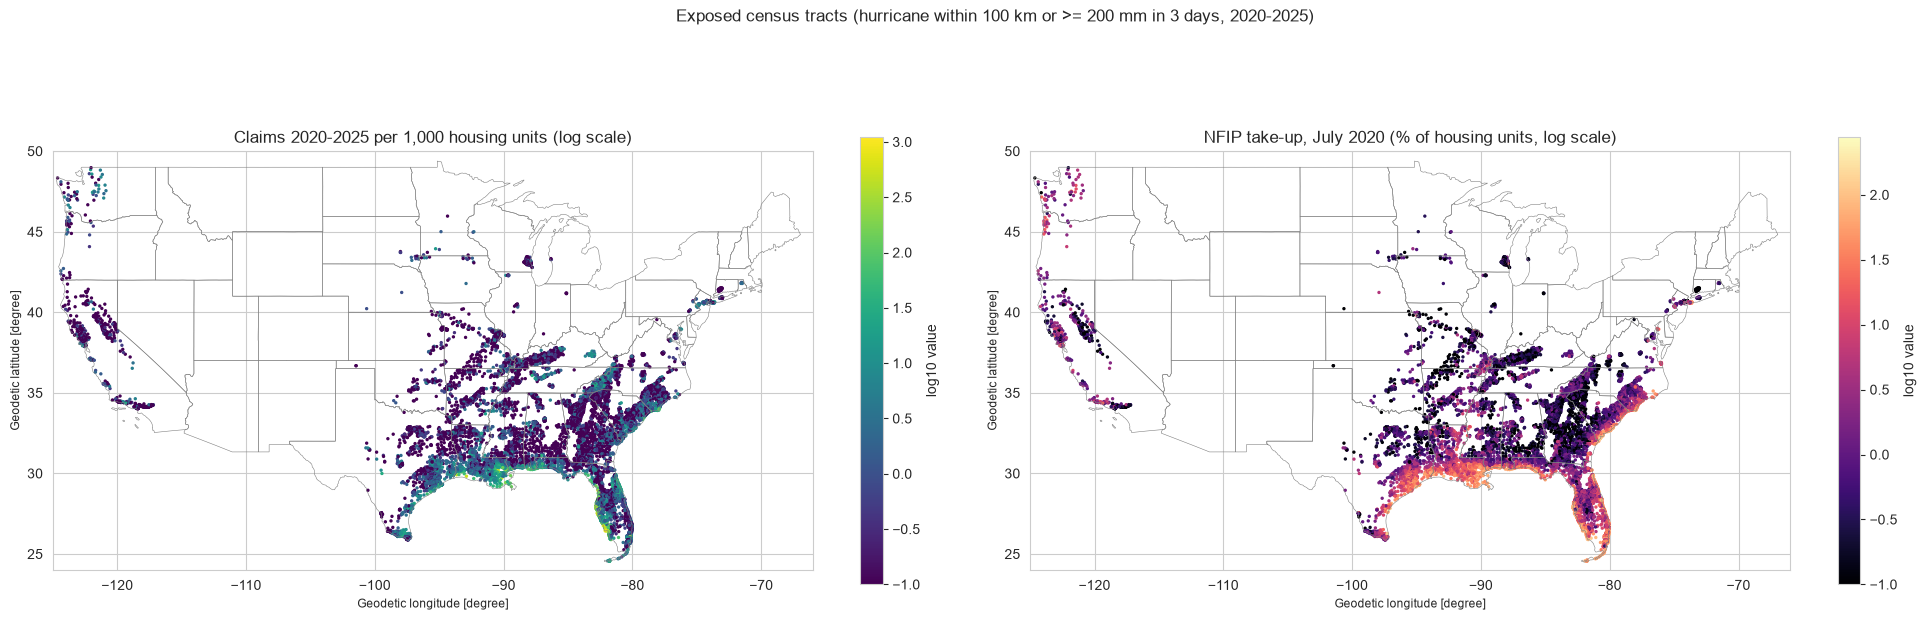

In [10]:
states = gpd.read_file(f'zip://{RAW_DIR / "boundaries" / "cb_2023_us_state_20m.zip"}')
states = states[~states['STUSPS'].isin(['AK', 'HI', 'PR'])]
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, column, title, cmap in [(axes[0], 'claims_per_1000_units', 'Claims 2020-2025 per 1,000 housing units (log scale)', 'viridis'),
                                (axes[1], 'take_up_2020_pct', 'NFIP take-up, July 2020 (% of housing units, log scale)', 'magma')]:
    states.boundary.plot(ax=ax, color='grey', linewidth=0.4)
    values = np.log10(exposed[column].clip(lower=0.1))
    points = ax.scatter(exposed['longitude'], exposed['latitude'], c=values, s=2, cmap=cmap)
    colorbar = plt.colorbar(points, ax=ax, shrink=0.7)
    colorbar.set_label('log10 value')
    ax.set_xlim(-125, -66)
    ax.set_ylim(24, 50)
    ax.set_title(title)
plt.suptitle('Exposed census tracts (hurricane within 100 km or >= 200 mm in 3 days, 2020-2025)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '09_exposed_tracts_claims_and_takeup.png', dpi=110)
plt.show()

---
# Section 6: First Look: Claims by Income, Within Bands of Similar Hazard (Lecture 03, discretization)

To compare like with like, we first build a **hazard score** that uses only the weather and place features (no ACS):
the expected claims per housing unit from a hazard-only model (Section 8 explains the model; here we use its
out-of-fold predictions). We cut this score into 5 bands, and **inside each band** compare income quintiles. Same
hazard band, different income: this is the simplest form of "even when hazard was similar".

In [11]:
HAZARD_FEATURES = ['hurricane_distance_km', 'tropical_storm_distance_km', 'storms_within_100km', 'max_3day_rain_mm',
                   'heavy_rain_days', 'coast_distance_km', 'nri_inland_flood_risk', 'nri_coastal_flood_risk', 'nri_hurricane_risk']
NEIGHBOURHOOD_FEATURES = ['median_income', 'pct_renter', 'pct_built_before_1980']
county_groups = exposed['county_geoid'].values
log_units = np.log(exposed['housing_units'].values)


def out_of_fold_poisson_trees(feature_list, target_column, offset, n_splits=5):
    """LightGBM with a Poisson loss; log(exposure) enters as a fixed offset (init_score). Folds are grouped by county."""
    predictions = np.zeros(len(exposed))
    for train_index, test_index in GroupKFold(n_splits=n_splits).split(exposed, groups=county_groups):
        model = lgb.LGBMRegressor(objective='poisson', n_estimators=400, learning_rate=0.03, num_leaves=31,
                                  min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  random_state=SEED, verbose=-1)
        model.fit(exposed.iloc[train_index][feature_list], exposed.iloc[train_index][target_column], init_score=offset[train_index])
        raw_score = model.predict(exposed.iloc[test_index][feature_list], raw_score=True)
        predictions[test_index] = np.exp(raw_score + offset[test_index])
    return predictions


exposed['expected_claims_hazard_only'] = out_of_fold_poisson_trees(HAZARD_FEATURES, 'claims_2020_2025', log_units)
exposed['hazard_band'] = pd.qcut(exposed['expected_claims_hazard_only'] / exposed['housing_units'], 5,
                                 labels=['H1 lowest', 'H2', 'H3', 'H4', 'H5 highest'])
exposed['income_quintile'] = pd.qcut(exposed['median_income'], 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])
exposed['renter_tercile'] = pd.qcut(exposed['pct_renter'], 3, labels=['few renters', 'middle', 'many renters'])
exposed['old_housing_tercile'] = pd.qcut(exposed['pct_built_before_1980'], 3, labels=['newer', 'middle', 'older'])


def pooled_rate(group, numerator, denominator, scale):
    return scale * group[numerator].sum() / group[denominator].sum()


band_table = (exposed.groupby(['hazard_band', 'income_quintile'])
              .apply(lambda group: pooled_rate(group, 'claims_2020_2025', 'housing_units', 1000)).unstack().round(1))
print('Claims per 1,000 housing units, by hazard band (rows) and income quintile (columns):')
print(band_table.to_string())
takeup_table = (exposed.groupby(['hazard_band', 'income_quintile'])
                .apply(lambda group: pooled_rate(group, 'pif_2020', 'housing_units', 100)).unstack().round(1))
print('\nTake-up in July 2020 (% of housing units insured), same layout:')
print(takeup_table.to_string())
per_policy_table = (exposed.groupby(['hazard_band', 'income_quintile'])
                    .apply(lambda group: pooled_rate(group, 'claims_2020_2025', 'pif_average', 100)).unstack().round(1))
print('\nClaims per 100 policies in force (average 2020-2025 PIF), same layout:')
print(per_policy_table.to_string())
band_table.to_csv(TABLE_DIR / '09_rq7_claims_per_1000_by_hazard_and_income.csv')
takeup_table.to_csv(TABLE_DIR / '09_rq7_takeup_by_hazard_and_income.csv')
per_policy_table.to_csv(TABLE_DIR / '09_rq7_claims_per_policy_by_hazard_and_income.csv')

Claims per 1,000 housing units, by hazard band (rows) and income quintile (columns):
income_quintile  Q1 lowest    Q2    Q3    Q4  Q5 highest
hazard_band                                             
H1 lowest              0.9   0.9   0.9   0.8         1.0
H2                     0.9   0.7   0.8   0.9         1.0
H3                     1.9   1.9   1.8   2.1         1.8
H4                     3.4   3.0   4.5   2.5         2.7
H5 highest            13.2  18.8  25.5  28.7        36.2

Take-up in July 2020 (% of housing units insured), same layout:
income_quintile  Q1 lowest    Q2    Q3    Q4  Q5 highest
hazard_band                                             
H1 lowest              1.0   0.9   1.0   1.0         1.3
H2                     1.5   1.3   1.4   1.9         2.2
H3                     4.2   5.9   7.9   9.4        13.9
H4                     6.7   7.5  10.3  14.5        17.3
H5 highest            14.7  19.1  25.0  31.5        44.9

Claims per 100 policies in force (average 2020-2025

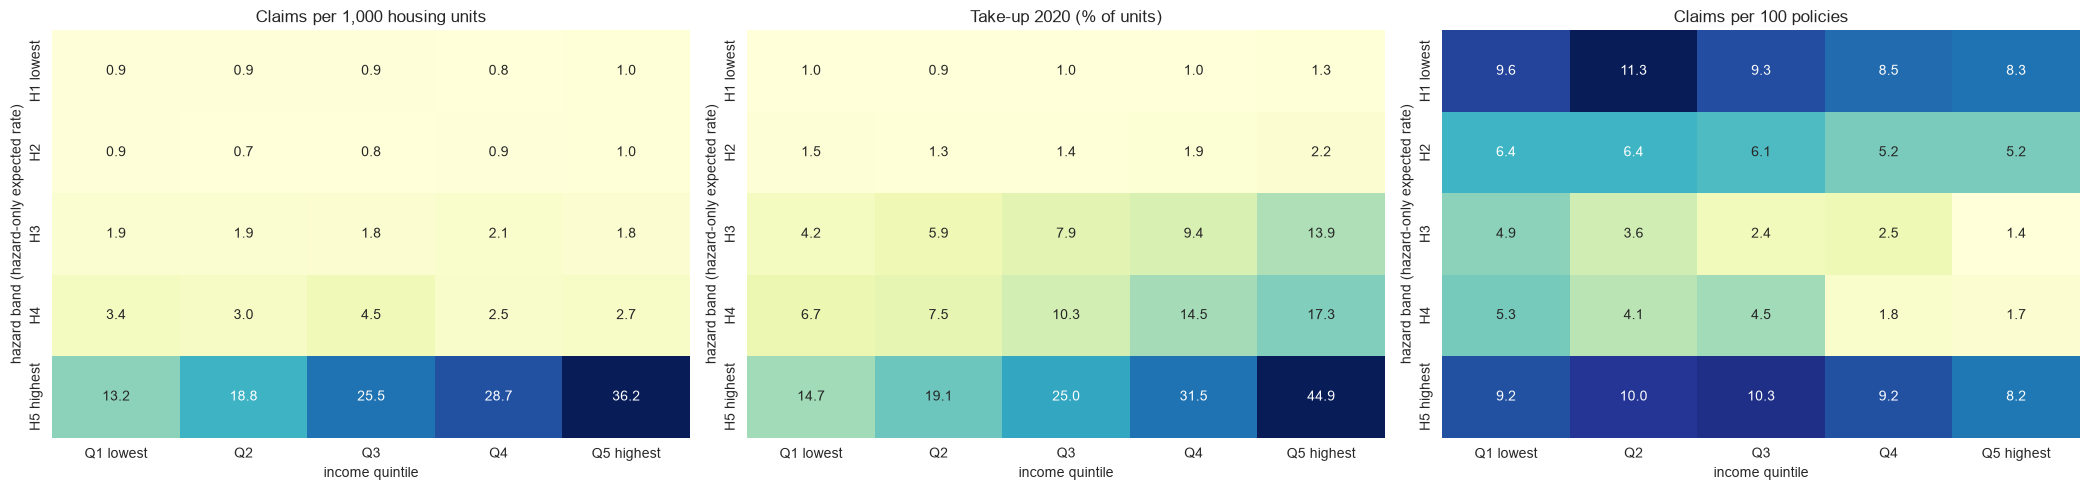

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, table, title in [(axes[0], band_table, 'Claims per 1,000 housing units'), (axes[1], takeup_table, 'Take-up 2020 (% of units)'),
                         (axes[2], per_policy_table, 'Claims per 100 policies')]:
    sns.heatmap(table, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel('income quintile')
    ax.set_ylabel('hazard band (hazard-only expected rate)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '09_rq7_hazard_band_heatmaps.png', dpi=110)
plt.show()

In [13]:
for column in ['renter_tercile', 'old_housing_tercile']:
    table = (exposed.groupby(['hazard_band', column])
             .apply(lambda group: pd.Series({'claims_per_1000': pooled_rate(group, 'claims_2020_2025', 'housing_units', 1000),
                                             'take_up_%': pooled_rate(group, 'pif_2020', 'housing_units', 100),
                                             'claims_per_100_policies': pooled_rate(group, 'claims_2020_2025', 'pif_average', 100)}))
             .unstack().round(1))
    print(f'\nBy {column}:')
    print(table.to_string())


By renter_tercile:
               claims_per_1000                       take_up_%                     claims_per_100_policies                    
renter_tercile     few renters middle many renters few renters middle many renters             few renters middle many renters
hazard_band                                                                                                                   
H1 lowest                  0.9    1.0          0.8         1.1    1.1          1.0                     8.6    9.9          9.3
H2                         0.9    1.0          0.6         1.9    1.6          1.3                     5.1    7.2          5.3
H3                         1.9    2.0          1.9        11.3    8.8          6.0                     1.8    2.4          3.4
H4                         3.4    3.8          2.5        14.2   13.3          8.4                     2.5    3.0          3.1
H5 highest                38.3   23.3         12.1        35.4   27.2         21.1         

**Reading Section 6.**
- **Claims per unit rise steeply with hazard** (about 1 per 1,000 units in band H1, 13-36 in H5). The hazard-only score
  works as intended.
- **Inside the highest hazard band, poorer tracts file far fewer claims:** 13.2 claims per 1,000 units in the lowest
  income quintile vs 36.2 in the highest. In bands H1-H4 the income pattern is flat.
- **Almost all of this is take-up.** In H5, 14.7% of housing units in the poorest tracts were insured in July 2020,
  against 44.9% in the richest. Claims **per policy** are about the same across incomes in H5 (8.2-10.3 per 100) and are
  even *higher* in poorer tracts in bands H2-H4.
- **Renters:** in H5, tracts with many renters file 12.1 claims per 1,000 units vs 38.3 with few renters; take-up is 21%
  vs 35%, and claims per policy are also lower (5.8 vs 10.9 per 100).
- **Older housing** files more claims per policy (in H5: 10.8 vs 7.0 per 100), with similar take-up.
- Caution: a hazard band is still wide. In H5, richer tracts may sit closer to the water than poorer ones. Section 7
  adds the hazard features and state effects directly.

---
# Section 7: Count Models: Poisson and Negative Binomial Regression (extension of Lecture 07)

**Why a count model?** The outcome is a **count** (0, 1, 2, ... claims), most tracts have small counts, and many have
zero. Linear regression would predict negative counts and treat a change from 0 to 5 like a change from 500 to 505.

**Poisson regression, step by step.**
1. Each tract *i* has an expected count $\mu_i$. We model its logarithm as a straight line:
   $\log \mu_i = \log(\text{units}_i) + \beta_0 + \beta_1 x_{1i} + \dots$
2. The term $\log(\text{units}_i)$ has no coefficient. It is the **offset** (the exposure). Moving it to the left side
   gives $\log(\mu_i / \text{units}_i)$: we really model the **rate per housing unit**.
3. $e^{\beta}$ is the **incidence rate ratio (IRR)**: the rate is multiplied by $e^{\beta}$ when $x$ goes up by one unit.
   We standardise every $x$, so the IRR is "per 1 standard deviation". IRR 0.80 = 20% fewer claims per housing unit.
4. Poisson assumes variance = mean. Claim counts are much more spread out (one tract has 0, its neighbour 300), so we use
   the **negative binomial** model, which adds a dispersion parameter $\alpha$: variance = $\mu + \alpha\mu^2$.

**Three models, one for each part of the identity:**

| Model | Count | Offset | Question |
|---|---|---|---|
| (a) claims per unit | claims 2020-2025 | log housing units | the full protection gap |
| (b) take-up | policies in force July 2020 | log housing units | are fewer homes insured? |
| (c) claims per policy | claims 2020-2025 | log average policies in force | do insured homes file less? |

Because all three are log-linear, IRR(a) is approximately IRR(b) x IRR(c). Every model includes all hazard features
and **state fixed effects** (each state has its own baseline: rules, markets, flood maps). Standard errors are clustered
by county.

In [14]:
model_data = exposed.copy()
model_data['log_income'] = np.log(model_data['median_income'])
model_data['log_hurricane_distance'] = np.log1p(model_data['hurricane_distance_km'])
model_data['log_tropical_distance'] = np.log1p(model_data['tropical_storm_distance_km'])
model_data['log_coast_distance'] = np.log1p(model_data['coast_distance_km'])
model_data['pif_2020_count'] = model_data['pif_2020'].round()
model_data['claims_count'] = model_data['claims_2020_2025'].round()
STANDARDISED = ['log_income', 'pct_renter', 'pct_built_before_1980', 'log_hurricane_distance', 'log_tropical_distance',
                'storms_within_100km', 'max_3day_rain_mm', 'heavy_rain_days', 'log_coast_distance',
                'nri_inland_flood_risk', 'nri_coastal_flood_risk', 'nri_hurricane_risk']
for column in STANDARDISED:
    model_data[f'z_{column}'] = (model_data[column] - model_data[column].mean()) / model_data[column].std()
model_data = model_data[model_data['state'].map(model_data['state'].value_counts()) >= 30].reset_index(drop=True)

NEIGHBOURHOOD_TERMS = 'z_log_income + z_pct_renter + z_pct_built_before_1980'
HAZARD_TERMS = ('z_log_hurricane_distance + z_log_tropical_distance + z_storms_within_100km + z_max_3day_rain_mm + z_heavy_rain_days'
                ' + z_log_coast_distance + z_nri_inland_flood_risk + z_nri_coastal_flood_risk + z_nri_hurricane_risk + C(state)')


def fit_negative_binomial(count_column, offset_column, data, terms):
    """Negative binomial (NB2) count model with an offset. If the estimated dispersion collapses to ~0, the data are not
    over-dispersed and the NB model is not identified; we then fit a Poisson GLM with county-clustered (robust) errors."""
    data = data[data[offset_column] > 0]
    county_codes = pd.factorize(data['county_geoid'])[0]
    result = smf.negativebinomial(f'{count_column} ~ {terms}', data=data, offset=np.log(data[offset_column])).fit(
        disp=False, maxiter=300, method='bfgs', cov_type='cluster', cov_kwds={'groups': county_codes})
    if result.params['alpha'] < 0.01 or not np.isfinite(result.bse).all():
        result = smf.glm(f'{count_column} ~ {terms}', data=data, family=sm.families.Poisson(),
                         offset=np.log(data[offset_column])).fit(cov_type='cluster', cov_kwds={'groups': county_codes})
        return result, len(data), 'Poisson GLM (robust SE)'
    return result, len(data), f'negative binomial (alpha {result.params["alpha"]:.2f})'


def rate_ratio_table(result, model_label, n_tracts, estimator=''):
    rows = []
    for term in ['z_log_income', 'z_pct_renter', 'z_pct_built_before_1980']:
        coefficient, standard_error = result.params[term], result.bse[term]
        rows.append({'model': model_label, 'variable (+1 SD)': term.replace('z_', ''), 'IRR': np.exp(coefficient),
                     'ci_low': np.exp(coefficient - 1.96 * standard_error), 'ci_high': np.exp(coefficient + 1.96 * standard_error),
                     'p_value': result.pvalues[term], 'tracts': n_tracts, 'estimator': estimator})
    return rows


model_data['claims_per_policy_ok'] = model_data['pif_average'] >= 5
irr_rows = []
specs = [('(a) claims per housing unit', 'claims_count', 'housing_units', model_data),
         ('(b) take-up (PIF 2020 per unit)', 'pif_2020_count', 'housing_units', model_data),
         ('(c) claims per policy in force', 'claims_count', 'pif_average', model_data[model_data['claims_per_policy_ok']])]
fitted_models = {}
for label, count_column, offset_column, data in specs:
    result, n_tracts, estimator = fit_negative_binomial(count_column, offset_column, data, NEIGHBOURHOOD_TERMS + ' + ' + HAZARD_TERMS)
    fitted_models[label] = result
    irr_rows += rate_ratio_table(result, label, n_tracts, estimator)
    print(f'{label:<34} tracts {n_tracts:>6,}   {estimator}')
irr_table = pd.DataFrame(irr_rows)
irr_table.round(4).to_csv(TABLE_DIR / '09_rq7_negative_binomial_irr.csv', index=False)
print()
print(irr_table.round(3).to_string(index=False))

(a) claims per housing unit        tracts 17,370   negative binomial (alpha 2.73)


(b) take-up (PIF 2020 per unit)    tracts 17,370   negative binomial (alpha 1.05)


(c) claims per policy in force     tracts 13,497   Poisson GLM (robust SE)

                          model      variable (+1 SD)   IRR  ci_low  ci_high  p_value  tracts                      estimator
    (a) claims per housing unit            log_income 0.997   0.882    1.128    0.964   17370 negative binomial (alpha 2.73)
    (a) claims per housing unit            pct_renter 0.682   0.619    0.751    0.000   17370 negative binomial (alpha 2.73)
    (a) claims per housing unit pct_built_before_1980 1.278   1.139    1.433    0.000   17370 negative binomial (alpha 2.73)
(b) take-up (PIF 2020 per unit)            log_income 1.343   1.249    1.445    0.000   17370 negative binomial (alpha 1.05)
(b) take-up (PIF 2020 per unit)            pct_renter 0.857   0.805    0.912    0.000   17370 negative binomial (alpha 1.05)
(b) take-up (PIF 2020 per unit) pct_built_before_1980 1.018   0.963    1.076    0.535   17370 negative binomial (alpha 1.05)
 (c) claims per policy in force            log_in

**How to read one row.** An IRR of 0.85 for `log_income` in model (a) would mean: a tract one standard deviation
richer has 15% fewer claims per housing unit, **at the same hazard and in the same state**. The same row in models (b)
and (c) tells us whether this comes from insurance take-up or from claims per policy.

In [15]:
check_rows = []
for variable in ['log_income', 'pct_renter', 'pct_built_before_1980']:
    values = irr_table.set_index(['model', 'variable (+1 SD)'])['IRR']
    take_up_part = values[('(b) take-up (PIF 2020 per unit)', variable)]
    per_policy_part = values[('(c) claims per policy in force', variable)]
    check_rows.append({'variable (+1 SD)': variable, 'IRR (a) claims per unit': values[('(a) claims per housing unit', variable)],
                       'IRR (b) take-up': take_up_part, 'IRR (c) claims per policy': per_policy_part,
                       '(b) x (c)': take_up_part * per_policy_part})
decomposition_table = pd.DataFrame(check_rows).round(3)
decomposition_table.to_csv(TABLE_DIR / '09_rq7_decomposition.csv', index=False)
print(decomposition_table.to_string(index=False))

     variable (+1 SD)  IRR (a) claims per unit  IRR (b) take-up  IRR (c) claims per policy  (b) x (c)
           log_income                    0.997            1.343                      0.825      1.108
           pct_renter                    0.682            0.857                      0.777      0.666
pct_built_before_1980                    1.278            1.018                      1.304      1.327


**Without hazard controls.** To see how much the hazard controls matter, we refit model (a) with only the neighbourhood
variables and state effects. If the IRRs change a lot, the raw comparison was mixing neighbourhood with hazard.

In [16]:
raw_result, raw_n, raw_estimator = fit_negative_binomial('claims_count', 'housing_units', model_data, NEIGHBOURHOOD_TERMS + ' + C(state)')
raw_rows = pd.DataFrame(rate_ratio_table(raw_result, '(a) without hazard controls', raw_n, raw_estimator))
comparison_with_hazard = pd.concat([raw_rows, irr_table[irr_table['model'] == '(a) claims per housing unit']])
print(comparison_with_hazard[['model', 'variable (+1 SD)', 'IRR', 'ci_low', 'ci_high']].round(3).to_string(index=False))

                      model      variable (+1 SD)   IRR  ci_low  ci_high
(a) without hazard controls            log_income 1.149   0.988    1.335
(a) without hazard controls            pct_renter 0.686   0.602    0.783
(a) without hazard controls pct_built_before_1980 1.311   1.133    1.517
(a) claims per housing unit            log_income 0.997   0.882    1.128
(a) claims per housing unit            pct_renter 0.682   0.619    0.751
(a) claims per housing unit pct_built_before_1980 1.278   1.139    1.433


**Reading Section 7.**
- **Renters (the clearest result).** One SD more renters (+24 points) means **32% fewer claims per housing unit**
  (IRR 0.68, 95% CI 0.62-0.75) at the same hazard and in the same state. It comes from both parts: 14% lower take-up
  (0.86) and 22% fewer claims per policy (0.78). Renters can only buy contents cover, are not covered by the mortgage
  requirement, and a landlord's building policy is filed by the landlord.
- **Income: no gap in claims per unit after controls** (IRR 1.00, CI 0.88-1.13), but **two effects cancel**: richer
  tracts insure much more (take-up IRR 1.34 per SD) and file fewer claims per policy (0.82, not significant). Without the
  hazard controls the income IRR is 1.15: part of the raw "richer areas claim more" pattern is because richer tracts sat
  in higher hazard (coast).
- **Older housing: more claims, not fewer** (IRR 1.28 per SD), driven by claims per policy (1.30) with the same take-up
  (1.02). Pre-1980 homes were mostly built before flood maps existed (pre-FIRM).
- The identity (b) x (c) = (a) holds well for renters (0.67 vs 0.68) and housing age (1.33 vs 1.28). For income it holds
  less well (1.11 vs 1.00), because model (c) uses a smaller sample (tracts with at least 5 policies) and a different
  estimator (Poisson; the negative binomial dispersion collapsed to zero).

---
# Section 8: A Tree Regressor With a Poisson Loss (Lectures 05 and 07)

The negative binomial model assumes straight-line effects on the log scale. A gradient-boosted tree model with a
**Poisson loss** (LightGBM `objective='poisson'`, with log housing units as a fixed offset) can learn thresholds such as
"within 30 km of the eye". We compare two feature sets with a **county-grouped 5-fold cross-validation** (all tracts of a
county are in the same fold, so the model cannot copy a neighbour's answer):
- **hazard only** (the 9 hazard features), and
- **hazard + neighbourhood** (adding income, % renter, % old housing).

If neighbourhood features lower the out-of-fold Poisson deviance, they carry information about claims that hazard
alone does not explain. The score is the mean Poisson deviance (lower is better); we also report the share of deviance
explained compared with a model that predicts the same rate everywhere.

In [17]:
exposed['expected_claims_hazard_plus_neighbourhood'] = out_of_fold_poisson_trees(HAZARD_FEATURES + NEIGHBOURHOOD_FEATURES, 'claims_2020_2025', log_units)
constant_rate = exposed['claims_2020_2025'].sum() / exposed['housing_units'].sum()
null_prediction = constant_rate * exposed['housing_units']
tree_rows = []
for label, prediction in [('constant rate (baseline)', null_prediction), ('hazard only', exposed['expected_claims_hazard_only']),
                          ('hazard + neighbourhood', exposed['expected_claims_hazard_plus_neighbourhood'])]:
    deviance = mean_poisson_deviance(exposed['claims_2020_2025'], np.clip(prediction, 1e-6, None))
    tree_rows.append({'features': label, 'mean_poisson_deviance': deviance})
tree_table = pd.DataFrame(tree_rows)
tree_table['deviance_explained_%'] = 100 * (1 - tree_table['mean_poisson_deviance'] / tree_table['mean_poisson_deviance'].iloc[0])
tree_table.round(3).to_csv(TABLE_DIR / '09_rq7_tree_poisson_cv.csv', index=False)
print(tree_table.round(3).to_string(index=False))

                features  mean_poisson_deviance  deviance_explained_%
constant rate (baseline)                 56.443                 0.000
             hazard only                 34.016                39.734
  hazard + neighbourhood                 33.507                40.635


**Reading the tree model.** Hazard alone explains about 40% of the Poisson deviance (34.0 vs 56.4) in county-grouped
cross-validation. Adding income, renters and housing age improves it only a little (33.5, about 1 more point). The
partial-dependence plots below agree in direction with Section 7 for renters (fewer claims) and older homes (more
claims). For income the tree shows *more* claims in richer tracts, because it has no state effects: income partly stands
in for region.

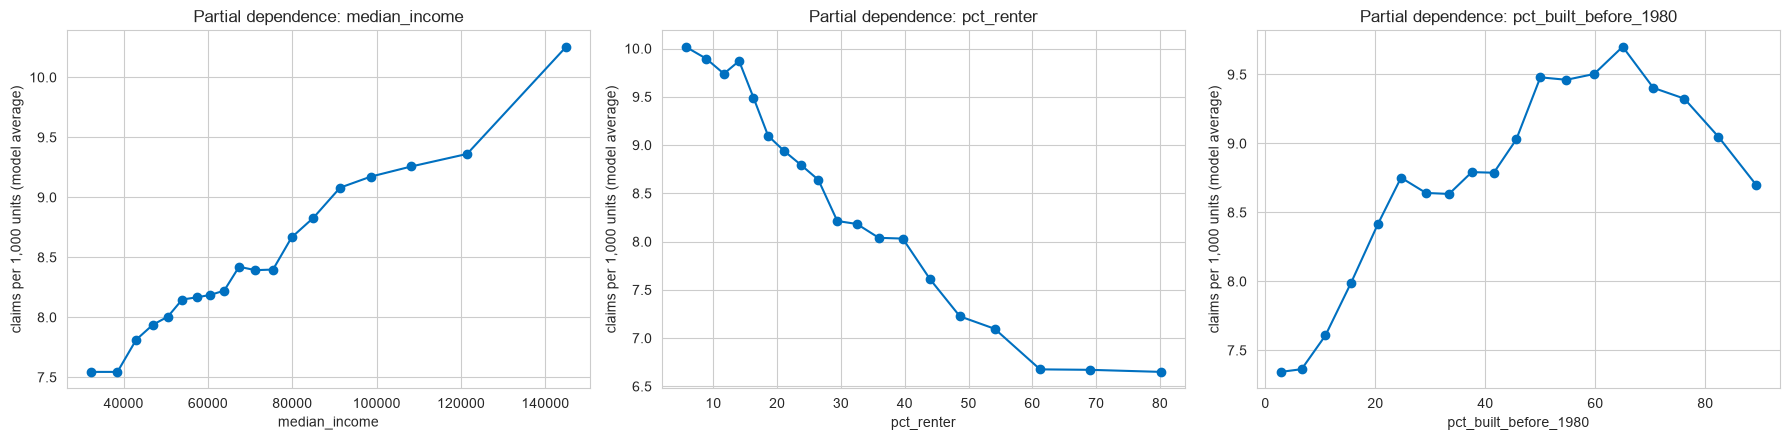

In [18]:
# One model on all exposed tracts, to look at how the neighbourhood features act (partial dependence by hand).
full_model = lgb.LGBMRegressor(objective='poisson', n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
all_features = HAZARD_FEATURES + NEIGHBOURHOOD_FEATURES
full_model.fit(exposed[all_features], exposed['claims_2020_2025'], init_score=log_units)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, feature in zip(axes, NEIGHBOURHOOD_FEATURES):
    grid_values = np.quantile(exposed[feature], np.linspace(0.05, 0.95, 19))
    average_rates = []
    for value in grid_values:
        modified = exposed[all_features].copy()
        modified[feature] = value
        average_rates.append(1000 * np.exp(full_model.predict(modified, raw_score=True)).mean())
    ax.plot(grid_values, average_rates, 'o-', color='#0070C0')
    ax.set_xlabel(feature)
    ax.set_ylabel('claims per 1,000 units (model average)')
    ax.set_title(f'Partial dependence: {feature}')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '09_rq7_partial_dependence.png', dpi=110)
plt.show()

---
# Section 9: Where Is the Gap? Observed vs Expected, and LISA Hotspots (Lecture 09-10, spatial statistics)

For every exposed tract we compare **observed** claims with the claims **expected from hazard alone** (the out-of-fold
hazard-only tree model). The **gap ratio** is $\log\frac{O + 0.5}{E + 0.5}$: below 0 means fewer claims than the hazard
predicts. Then we ask whether low ratios **cluster in space**:
- **Global Moran's I**: do neighbouring tracts have similar gap ratios? (neighbours = the 8 nearest tract points)
- **LISA** (local Moran): a value for each tract. **Low-Low** = a tract with fewer claims than expected surrounded by
  tracts that also have fewer claims than expected: a **protection-gap hotspot**. **High-High** = the opposite.

In [19]:
from libpysal.weights import KNN
from esda.moran import Moran, Moran_Local

exposed['gap_log_ratio'] = np.log((exposed['claims_2020_2025'] + 0.5) / (exposed['expected_claims_hazard_only'] + 0.5))
projected = gpd.GeoSeries(gpd.points_from_xy(exposed['longitude'], exposed['latitude']), crs=4326).to_crs(5070)
coordinates_km = np.column_stack([projected.x / 1000, projected.y / 1000])
neighbour_weights = KNN.from_array(coordinates_km, k=8)
neighbour_weights.transform = 'r'
np.random.seed(SEED)    # esda's global Moran permutation test uses NumPy's global random state (no seed argument)
global_moran = Moran(exposed['gap_log_ratio'].values, neighbour_weights, permutations=199)
print(f"Global Moran's I of the gap ratio = {global_moran.I:.3f} (expected {global_moran.EI:.4f}), permutation p = {global_moran.p_sim:.3f}")
local_moran = Moran_Local(exposed['gap_log_ratio'].values, neighbour_weights, permutations=199, seed=SEED)
quadrant_names = {1: 'High-High (more claims than hazard predicts)', 2: 'Low-High', 3: 'Low-Low (protection-gap hotspot)', 4: 'High-Low'}
exposed['lisa_cluster'] = np.where(local_moran.p_sim < 0.05, pd.Series(local_moran.q).map(quadrant_names), 'not significant')
print(exposed['lisa_cluster'].value_counts().to_string())

Global Moran's I of the gap ratio = 0.450 (expected -0.0001), permutation p = 0.005


lisa_cluster
not significant                                 11669
Low-Low (protection-gap hotspot)                 2786
High-High (more claims than hazard predicts)     2261
High-Low                                          426
Low-High                                          334


In [20]:
lisa_profile = exposed.groupby('lisa_cluster').apply(lambda group: pd.Series({
    'tracts': len(group), 'housing_units_M': group['housing_units'].sum() / 1e6,
    'observed_claims': group['claims_2020_2025'].sum(), 'expected_claims_hazard_only': group['expected_claims_hazard_only'].sum(),
    'claims_per_1000_units': pooled_rate(group, 'claims_2020_2025', 'housing_units', 1000),
    'take_up_2020_%': pooled_rate(group, 'pif_2020', 'housing_units', 100),
    'claims_per_100_policies': pooled_rate(group, 'claims_2020_2025', 'pif_average', 100),
    'median_income': group['median_income'].median(), 'median_pct_renter': group['pct_renter'].median(),
    'median_pct_built_before_1980': group['pct_built_before_1980'].median(),
    'median_coast_distance_km': group['coast_distance_km'].median(),
    'top_states': ', '.join(group['state'].value_counts().head(3).index)}))
lisa_profile.round(2).to_csv(TABLE_DIR / '09_rq7_lisa_profile.csv')
print(lisa_profile.round(2).to_string())

                                              tracts  housing_units_M  observed_claims  expected_claims_hazard_only  claims_per_1000_units  take_up_2020_%  claims_per_100_policies  median_income  median_pct_renter  median_pct_built_before_1980  median_coast_distance_km  top_states
lisa_cluster                                                                                                                                                                                                                                                                             
High-High (more claims than hazard predicts)    2261             4.09        149946.67                     53993.33                  36.66           25.57                    14.50        68297.0              25.12                         41.79                     16.60  FL, LA, TX
High-Low                                         426             0.74          3220.28                      6960.60                   4.37           13.94

**Reading the LISA map and profile.**
- The gap ratio is strongly clustered in space: **Moran's I = 0.45** (p = 0.005).
- **2,786 tracts (5.3 M housing units) are Low-Low protection-gap hotspots.** The hazard-only model expected about
  50,000 claims there; only about 1,700 were filed (0.33 per 1,000 units). Take-up in July 2020 was 7.5%, against 25.6%
  in the High-High tracts.
- The hotspots are mostly **inland heavy-rain areas, not the coast:** metro Atlanta, the Carolinas Piedmont, Arkansas
  / Oklahoma, Chicago, Connecticut, and parts of Florida, Texas and California (atmospheric rivers). They had storm rain
  but sit far from mapped floodplains, which matches Nelson-Mercer et al.'s finding that much damage is pluvial and
  outside the SFHA.
- Surprise: the hotspots are **not poorer** (median income $73,813 vs $68,297 in High-High tracts). The spatial gap is
  about **where** people believe they are safe (low take-up away from the coast), more than about income.

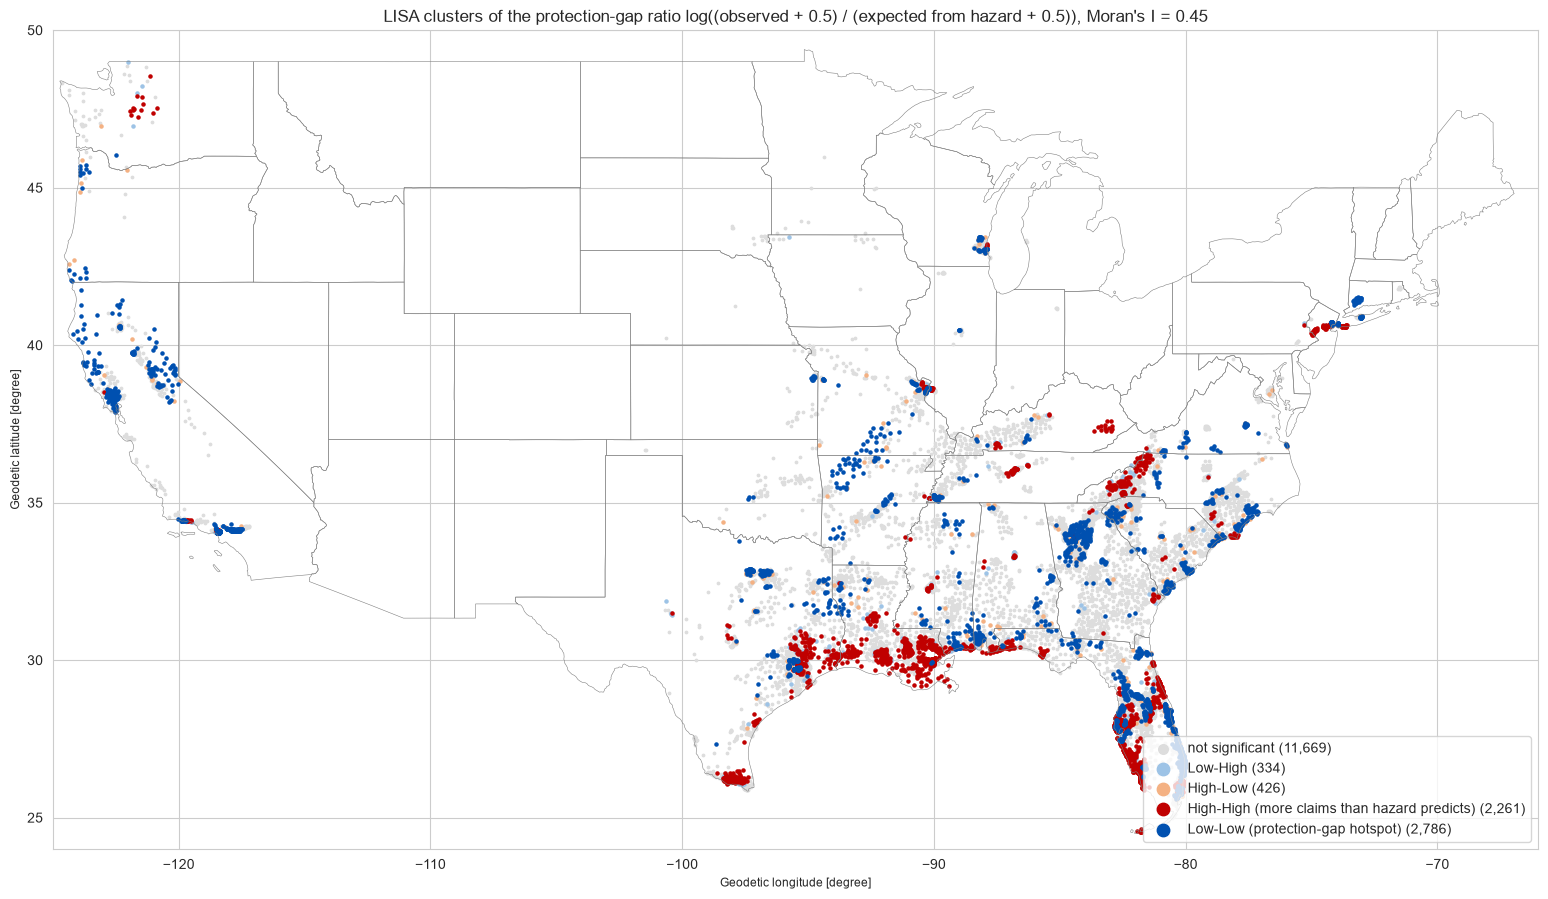

In [21]:
lisa_colors = {'High-High (more claims than hazard predicts)': '#C00000', 'Low-Low (protection-gap hotspot)': '#0050B0',
               'Low-High': '#9DC3E6', 'High-Low': '#F4B183', 'not significant': '#DDDDDD'}
fig, ax = plt.subplots(figsize=(16, 9))
states.boundary.plot(ax=ax, color='grey', linewidth=0.4)
for cluster_name in ['not significant', 'Low-High', 'High-Low', 'High-High (more claims than hazard predicts)', 'Low-Low (protection-gap hotspot)']:
    subset = exposed[exposed['lisa_cluster'] == cluster_name]
    ax.scatter(subset['longitude'], subset['latitude'], s=3 if cluster_name == 'not significant' else 5,
               color=lisa_colors[cluster_name], label=f'{cluster_name} ({len(subset):,})')
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.legend(loc='lower right', markerscale=4)
ax.set_title(f"LISA clusters of the protection-gap ratio log((observed + 0.5) / (expected from hazard + 0.5)), Moran's I = {global_moran.I:.2f}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / '09_rq7_lisa_protection_gap.png', dpi=110)
plt.show()

---
# Section 10: Sensitivity: Does the Answer Depend on the Exposure Definition?

We refit model (a) and (b) with a **narrower** definition (hurricane within 50 km or >= 250 mm in 3 days) and a
**wider** one (within 150 km or >= 150 mm).

In [22]:
sensitivity_rows = []
for label, hurricane_km, rain_mm in [('narrow: 50 km or 250 mm', 50, 250), ('main: 100 km or 200 mm', 100, 200), ('wide: 150 km or 150 mm', 150, 150)]:
    subset = tracts[usable & exposed_mask(tracts, hurricane_km, rain_mm)].copy()
    subset['log_income'] = np.log(subset['median_income'])
    subset['log_hurricane_distance'] = np.log1p(subset['hurricane_distance_km'])
    subset['log_tropical_distance'] = np.log1p(subset['tropical_storm_distance_km'])
    subset['log_coast_distance'] = np.log1p(subset['coast_distance_km'])
    subset['claims_count'] = subset['claims_2020_2025'].round()
    subset['pif_2020_count'] = subset['pif_2020'].round()
    for column in STANDARDISED:
        subset[f'z_{column}'] = (subset[column] - subset[column].mean()) / subset[column].std()
    subset = subset[subset['state'].map(subset['state'].value_counts()) >= 30]
    for model_label, count_column in [('(a) claims per unit', 'claims_count'), ('(b) take-up', 'pif_2020_count')]:
        result, n_tracts, estimator = fit_negative_binomial(count_column, 'housing_units', subset, NEIGHBOURHOOD_TERMS + ' + ' + HAZARD_TERMS)
        for row in rate_ratio_table(result, model_label, n_tracts, estimator):
            row['exposure_definition'] = label
            sensitivity_rows.append(row)
sensitivity_table = pd.DataFrame(sensitivity_rows).pivot_table(index=['exposure_definition', 'model'], columns='variable (+1 SD)', values='IRR').round(3)
sensitivity_table.to_csv(TABLE_DIR / '09_rq7_sensitivity.csv')
print(sensitivity_table.to_string())

variable (+1 SD)                             log_income  pct_built_before_1980  pct_renter
exposure_definition     model                                                             
main: 100 km or 200 mm  (a) claims per unit       0.997                  1.278       0.682
                        (b) take-up               1.343                  1.018       0.857
narrow: 50 km or 250 mm (a) claims per unit       0.952                  1.167       0.641
                        (b) take-up               1.396                  1.007       0.843
wide: 150 km or 150 mm  (a) claims per unit       1.039                  1.325       0.648
                        (b) take-up               1.209                  1.029       0.746


In [23]:
results_rq7 = {'exposed_tracts': int(len(exposed)), 'irr': irr_table.round(4).to_dict('records'),
               'decomposition': decomposition_table.to_dict('records'), 'tree_cv': tree_table.round(4).to_dict('records'),
               'moran_I': float(global_moran.I), 'moran_p': float(global_moran.p_sim),
               'lisa_profile': lisa_profile.round(3).reset_index().to_dict('records')}
json.dump(results_rq7, open(TABLE_DIR / '09_rq7_results.json', 'w'), indent=2, default=str)

---
## The numbers behind the answer

Read back from the saved tables (`tables/09_*`).

In [24]:
results_saved = json.load(open(TABLE_DIR / '09_rq7_results.json'))
irr_saved = pd.read_csv(TABLE_DIR / '09_rq7_negative_binomial_irr.csv')
sensitivity_saved = pd.read_csv(TABLE_DIR / '09_rq7_sensitivity.csv')
tree_saved = pd.read_csv(TABLE_DIR / '09_rq7_tree_poisson_cv.csv').set_index('features')
lisa_saved = pd.read_csv(TABLE_DIR / '09_rq7_lisa_profile.csv').set_index('lisa_cluster')
takeup_saved = pd.read_csv(TABLE_DIR / '09_rq7_takeup_by_hazard_and_income.csv').set_index('hazard_band')
claims_band_saved = pd.read_csv(TABLE_DIR / '09_rq7_claims_per_1000_by_hazard_and_income.csv').set_index('hazard_band')
rows = [('exposed tracts', results_saved['exposed_tracts'], '09_rq7_results.json'),
        ('exposed tracts: housing units (M) / claims / share of tracts with no claim',
         f"{exposed['housing_units'].sum() / 1e6:.1f} / {exposed['claims_2020_2025'].sum():,.0f} / {(exposed['claims_2020_2025'] < 0.5).mean() * 100:.1f}%", 'this notebook')]
for _, r in irr_saved.iterrows():
    rows.append((f"IRR {r['model']}, {r['variable (+1 SD)']} [95% CI]", f"{r['IRR']:.2f} [{r['ci_low']:.2f}-{r['ci_high']:.2f}], {r['estimator']}", '09_rq7_negative_binomial_irr'))
renter_a = sensitivity_saved[sensitivity_saved['model'] == '(a) claims per unit']['pct_renter']
rows.append(('renter IRR (a) across the 3 exposure definitions', f'{renter_a.min():.2f}-{renter_a.max():.2f}', '09_rq7_sensitivity'))
for features in tree_saved.index:
    rows.append((f'tree (Poisson loss) deviance explained: {features} %', tree_saved.loc[features, 'deviance_explained_%'], '09_rq7_tree_poisson_cv'))
top_band = takeup_saved.index[-1]
rows += [(f'take-up % in {top_band}: Q1 lowest vs Q5 highest income', f"{takeup_saved.loc[top_band, 'Q1 lowest']} vs {takeup_saved.loc[top_band, 'Q5 highest']}", '09_rq7_takeup_by_hazard_and_income'),
         (f'claims per 1,000 units in {top_band}: Q1 vs Q5', f"{claims_band_saved.loc[top_band, 'Q1 lowest']} vs {claims_band_saved.loc[top_band, 'Q5 highest']}", '09_rq7_claims_per_1000_by_hazard_and_income'),
         ("Moran's I of observed/expected ratio (p)", f"{results_saved['moran_I']:.2f} ({results_saved['moran_p']:.3f})", '09_rq7_results.json')]
for cluster in lisa_saved.index:
    r = lisa_saved.loc[cluster]
    rows.append((f'LISA {cluster[:40]}', f"{int(r['tracts']):,} tracts, {r['housing_units_M']} M units, observed {r['observed_claims']:,.0f} vs expected {r['expected_claims_hazard_only']:,.0f}, "
                 f"take-up {r['take_up_2020_%']}%, top states {r['top_states']}", '09_rq7_lisa_profile'))
answer_numbers = show_answer_numbers(rows, '09_rq7')

                                                                  quantity                                                                                                   value                                      source
                                                            exposed tracts                                                                                                   17476                         09_rq7_results.json
exposed tracts: housing units (M) / claims / share of tracts with no claim                                                                                  30.6 / 212,628 / 43.9%                               this notebook
                      IRR (a) claims per housing unit, log_income [95% CI]                                                        1.00 [0.88-1.13], negative binomial (alpha 2.73)                09_rq7_negative_binomial_irr
                      IRR (a) claims per housing unit, pct_renter [95% CI]                                  

---
# Research Question -> Answer

> **RQ7. Do census tracts with lower income, more renters or older housing file fewer NFIP claims per housing unit
> exposed, even when storm and rain hazard was similar?**

(Numbers from the `answer_numbers` table above.)

**Data.** 17,476 exposed tracts (hurricane track within 100 km or >= 200 mm of rain in 3 days, 2020-2025) in 33 states,
30.6 M housing units, 212,628 claims (78% of all claims). 43.9% of exposed tracts filed no claim at all.

**Answer: yes for renters, no for income once hazard and state are controlled, and the opposite for older housing.
The gap is mostly a take-up gap.**

| +1 SD in ... | (a) claims per unit | (b) take-up (PIF 2020 per unit) | (c) claims per policy |
|---|---|---|---|
| % renters (+24 pts) | **0.68** [0.62-0.75] | 0.86 [0.80-0.91] | 0.78 [0.65-0.92] |
| log income | 1.00 [0.88-1.13] | **1.34** [1.25-1.45] | 0.82 [0.65-1.05] |
| % built before 1980 (+28 pts) | **1.28** [1.14-1.43] | 1.02 [0.96-1.08] | 1.30 [1.10-1.55] |

(Incidence rate ratios from negative binomial models (a, b) and a Poisson GLM (c) with all hazard features, state fixed
effects and county-clustered 95% CIs.)

1. **Renter-heavy tracts file about one third fewer claims per housing unit** at the same hazard, through both lower
   take-up and fewer claims per policy. This holds under all three exposure definitions (IRR 0.64-0.68).
2. **Lower income does not reduce claims per unit after controls,** but only because two effects cancel: poorer tracts
   insure far less (in the highest hazard band, 14.7% of units insured in the poorest quintile vs 44.9% in the richest)
   while their policies claim at least as often. In the raw highest-hazard band the poorest tracts filed 13.2 claims per
   1,000 units vs 36.2 in the richest: the protection gap is real, but it is a **take-up gap**.
3. **Older housing files more claims** (pre-FIRM homes get damaged more often), not fewer.
4. **Hazard explains about 40%** of the variation (tree model, county-grouped CV); neighbourhood features add about 1 point.
5. **Where is the gap?** The observed/expected ratio is strongly clustered (Moran's I = 0.45). 2,786 Low-Low hotspot tracts
   (5.3 M units) filed about 1,700 claims where hazard predicted about 50,000; their take-up was 7.5%. They are mainly
   **inland heavy-rain areas** (Atlanta, the Carolinas, Arkansas/Oklahoma, Chicago, Connecticut) and are not poorer than
   the High-High tracts.

**Important limits (claims depend on policy take-up).** A tract with few claims is not a tract with little damage: an
uninsured flooded home leaves no NFIP record. That is why we used the policies file to separate take-up from claim rate.
Other limits: the hazard is measured at one point per tract; vacant/seasonal homes are in the denominator; ACS describes
neighbourhoods, not policyholders; private flood insurance is not observed; policy and claim codes were moved from 2010 to
2020 tracts by land area (6.8% of claims, 16.7% of 2020 policies).

**Leakage and causality notes.**
- The outcome (claims) is never used as a feature. The hazard-only "expected claims" are out-of-fold predictions grouped
  by county, so a tract's own claims never enter its own expectation.
- Take-up is measured on 1 July 2020, **before** the events, so post-flood purchases (reverse causality) do not inflate it.
- The hazard features describe the 2020-2025 weather itself. That is intended: we condition on the flood that happened.
- The NRI risk scores are partly built from historical loss data; they are used only as hazard controls.

**References for this notebook.**
- FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Policies - v3* (NfipPoliciesV3.parquet, 74,778,941 records). https://www.fema.gov/openfema-data-page/nfip-redacted-policies-v3
- U.S. Census Bureau. *ACS 2019-2023 5-year Summary File* (tables B25001, B25003, B19013, B25034, B25035, B01003); *2023 Gazetteer tract file*; *2020-2010 census tract relationship file*. https://www.census.gov/geographies/reference-files/time-series/geo/relationship-files.html
- Bradt, J., Kousky, C. & Wing, O. (2021). Voluntary purchases and adverse selection in the market for flood insurance. *Journal of Environmental Economics and Management* 110, 102515.
- Amornsiripanitch, N., Biswas, S., Orellana-Li, J. & Zink, D. (2025). Measuring flood underinsurance in the USA. *Nature Climate Change* 15.
- Gourevitch, J., Snyder, M. & Kousky, C. (2025). Effects of risk-based pricing reform on flood insurance uptake. *Journal of Catastrophe Risk and Resilience*.
- Nelson-Mercer, B., Kim, T., Tran, V. N. & Ivanov, V. (2025). Pluvial flood impacts and policyholder responses throughout the United States. *npj Natural Hazards*.
- Kousky, C. & Michel-Kerjan, E. (2017). Examining flood insurance claims in the United States: Six key findings. *Journal of Risk and Insurance* 84(3), 819-850.
- Cameron, A. C. & Trivedi, P. K. (2013). *Regression Analysis of Count Data* (2nd ed.). Cambridge University Press.
- Anselin, L. (1995). Local indicators of spatial association - LISA. *Geographical Analysis* 27(2), 93-115.